## Problem Statement

### Business Context

Business communities in the United States are facing high demand for human resources, but one of the constant challenges is identifying and attracting the right talent, which is perhaps the most important element in remaining competitive. Companies in the United States look for hard-working, talented, and qualified individuals both locally as well as abroad.

The Immigration and Nationality Act (INA) of the US permits foreign workers to come to the United States to work on either a temporary or permanent basis. The act also protects US workers against adverse impacts on their wages or working conditions by ensuring US employers' compliance with statutory requirements when they hire foreign workers to fill workforce shortages. The immigration programs are administered by the Office of Foreign Labor Certification (OFLC).

OFLC processes job certification applications for employers seeking to bring foreign workers into the United States and grants certifications in those cases where employers can demonstrate that there are not sufficient US workers available to perform the work at wages that meet or exceed the wage paid for the occupation in the area of intended employment.

### Objective

In FY 2016, the OFLC processed 775,979 employer applications for 1,699,957 positions for temporary and permanent labor certifications. This was a nine percent increase in the overall number of processed applications from the previous year. The process of reviewing every case is becoming a tedious task as the number of applicants is increasing every year.

The increasing number of applicants every year calls for a Machine Learning based solution that can help in shortlisting the candidates having higher chances of VISA approval. OFLC has hired the firm EasyVisa for data-driven solutions. You as a data  scientist at EasyVisa have to analyze the data provided and, with the help of a classification model:

* Facilitate the process of visa approvals.
* Recommend a suitable profile for the applicants for whom the visa should be certified or denied based on the drivers that significantly influence the case status.

### Data Description

The data contains the different attributes of employee and the employer. The detailed data dictionary is given below.

* case_id: ID of each visa application
* continent: Information of continent the employee
* education_of_employee: Information of education of the employee
* has_job_experience: Does the employee has any job experience? Y= Yes; N = No
* requires_job_training: Does the employee require any job training? Y = Yes; N = No
* no_of_employees: Number of employees in the employer's company
* yr_of_estab: Year in which the employer's company was established
* region_of_employment: Information of foreign worker's intended region of employment in the US.
* prevailing_wage:  Average wage paid to similarly employed workers in a specific occupation in the area of intended employment. The purpose of the prevailing wage is to ensure that the foreign worker is not underpaid compared to other workers offering the same or similar service in the same area of employment.
* unit_of_wage: Unit of prevailing wage. Values include Hourly, Weekly, Monthly, and Yearly.
* full_time_position: Is the position of work full-time? Y = Full Time Position; N = Part Time Position
* case_status:  Flag indicating if the Visa was certified or denied

## Installing and Importing the necessary libraries

In [ ]:
# Installing the libraries with the specified version.
!pip install numpy==1.25.2 pandas==1.5.3 scikit-learn==1.5.2 matplotlib==3.7.1 seaborn==0.13.1 xgboost==2.0.3 -q --user

  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.


**Note**: *After running the above cell, kindly restart the notebook kernel and run all cells sequentially from the below.*

In [ ]:
# Library to suppress warnings or deprecation notes
import warnings
warnings.filterwarnings('ignore')

# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# Libraries to help with data visualization
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

# Libraries to split data, impute missing values
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# Libraries to import decision tree classifier and different ensemble classifiers
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.tree import DecisionTreeClassifier

# Libtune to tune model, get different metric scores
from sklearn import metrics
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import StratifiedKFold

# To oversample and undersample data
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

## Import Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/AIML/Project3/EasyVisa.csv')

In [ ]:
data = df.copy()

## Overview of the Dataset

#### View the first and last 5 rows of the dataset

In [ ]:
data.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


In [ ]:
data.tail()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
25475,EZYV25476,Asia,Bachelor's,Y,Y,2601,2008,South,77092.57,Year,Y,Certified
25476,EZYV25477,Asia,High School,Y,N,3274,2006,Northeast,279174.79,Year,Y,Certified
25477,EZYV25478,Asia,Master's,Y,N,1121,1910,South,146298.85,Year,N,Certified
25478,EZYV25479,Asia,Master's,Y,Y,1918,1887,West,86154.77,Year,Y,Certified
25479,EZYV25480,Asia,Bachelor's,Y,N,3195,1960,Midwest,70876.91,Year,Y,Certified


#### Understand the shape of the dataset

In [ ]:
data.shape

(25480, 12)

**OBSERVATIONS** :
- There are 25480 rows and 12 columns

#### Check the data types of the columns for the dataset

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   case_id                25480 non-null  object 
 1   continent              25480 non-null  object 
 2   education_of_employee  25480 non-null  object 
 3   has_job_experience     25480 non-null  object 
 4   requires_job_training  25480 non-null  object 
 5   no_of_employees        25480 non-null  int64  
 6   yr_of_estab            25480 non-null  int64  
 7   region_of_employment   25480 non-null  object 
 8   prevailing_wage        25480 non-null  float64
 9   unit_of_wage           25480 non-null  object 
 10  full_time_position     25480 non-null  object 
 11  case_status            25480 non-null  object 
dtypes: float64(1), int64(2), object(9)
memory usage: 2.3+ MB


In [ ]:
data.isnull().sum()

,0
case_id,0
continent,0
education_of_employee,0
has_job_experience,0
requires_job_training,0
no_of_employees,0
yr_of_estab,0
region_of_employment,0
prevailing_wage,0
unit_of_wage,0


In [ ]:
data.duplicated().sum()

np.int64(0)

**OBSERVATIONS**:
- There are 3 numeric columns (2 int + 1 float) and 9 categorical columns
- There is no missing data and no duplicates

## Exploratory Data Analysis (EDA)

#### Let's check the statistical summary of the data

In [ ]:
data.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
case_id,25480,25480,EZYV25480,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
continent,25480,6,Asia,16861,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education_of_employee,25480,4,Bachelor's,10234,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_job_experience,25480,2,Y,14802,NaN,NaN,NaN,NaN,NaN,NaN,NaN
requires_job_training,25480,2,N,22525,NaN,NaN,NaN,NaN,NaN,NaN,NaN
no_of_employees,25480.0,NaN,NaN,NaN,5667.04321,22877.928848,-26.0,1022.0,2109.0,3504.0,602069.0
yr_of_estab,25480.0,NaN,NaN,NaN,1979.409929,42.366929,1800.0,1976.0,1997.0,2005.0,2016.0
region_of_employment,25480,5,Northeast,7195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
prevailing_wage,25480.0,NaN,NaN,NaN,74455.814592,52815.942327,2.1367,34015.48,70308.21,107735.5125,319210.27
unit_of_wage,25480,4,Year,22962,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**OBSERVATIONS**:
- It seems that for 'no_of_employees' columns there are some negative values. We can go ahead and treat them if they aren't significant. 1 approach would be to convert them to the same positive/absolute value
- The range of 'prevailing_wage' column is quite large. Based on the min, max and mean values, data may be skewed.

#### Fixing the negative values in number of employees columns

In [ ]:
data[data['no_of_employees']<0]['no_of_employees'].count()

np.int64(33)

In [ ]:
data[data['no_of_employees']<0]['no_of_employees'].unique()

array([-25, -11, -17, -26, -14])

In [ ]:
data['no_of_employees'] = data['no_of_employees'].abs()

In [ ]:
data['no_of_employees']

,no_of_employees
0,14513
1,2412
2,44444
3,98
4,1082
...,...
25475,2601
25476,3274
25477,1121
25478,1918


**OBSERVATIONS**:
- I converted the negative values of 'no_of_employees' to the respective positive value as negative value does not make sense, and probably it is a data error

#### Let's check the count of each unique category in each of the categorical variables

In [ ]:
cat_col = list(data.select_dtypes("object").columns)

for col in cat_col:
    print(data[col].value_counts())
    print("-" * 50)

case_id
EZYV25480    1
EZYV01       1
EZYV02       1
EZYV03       1
EZYV04       1
            ..
EZYV13       1
EZYV12       1
EZYV11       1
EZYV10       1
EZYV09       1
Name: count, Length: 25480, dtype: int64
--------------------------------------------------
continent
Asia             16861
Europe            3732
North America     3292
South America      852
Africa             551
Oceania            192
Name: count, dtype: int64
--------------------------------------------------
education_of_employee
Bachelor's     10234
Master's        9634
High School     3420
Doctorate       2192
Name: count, dtype: int64
--------------------------------------------------
has_job_experience
Y    14802
N    10678
Name: count, dtype: int64
--------------------------------------------------
requires_job_training
N    22525
Y     2955
Name: count, dtype: int64
--------------------------------------------------
region_of_employment
Northeast    7195
South        7017
West         6586
Midwest      

**OBSERVATIONS**:

---


Features / Columns:

---


- case_id : unique id: We can drop this column as it is not useful for data analysis and models

Categorical values:
- continent: Asia has more significantly more data entries than other continents
- education_of_employee : Bachelors and Masters have more data.
- unit_of_wage : This column too has uneven distribution with year having the highest data

Dual values:
- has_job_experience: Relatively even distribution
- requires_job_training : Data is relatively high for no job training required
- full_time_position : Data is relatively high for fulltime as yes
- case_status: Has values: Certified or Denied. This is our target variable. We have almost twice the number of Certified cases as compared to Denied.



---


Treatment:

---

- We can perform Label encoding on the fields which have dual values later.
- We can combine prevailing_wage and unit_of_wage to reduce dimensions. More details covered later.
- The number of unique values in the other categorical columns are not much. So we can perform one hot encoding using pd.get_dummies() method.



In [ ]:
data.drop(['case_id'],axis=1,inplace=True)

**OBSERVATIONS**:
- Dropping the case_id column as it is just a unique_identifier and won't be needed for univariant/bivariant analysis or model building

### Univariate Analysis

In [ ]:
def histogram_boxplot(data, feature, figsize=(15, 10), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (15,10))
    kde: whether to show the density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a triangle will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

In [ ]:
# function to create labeled barplots


def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 1, 5))
    else:
        plt.figure(figsize=(n + 1, 5))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n].sort_values(),
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot

#### Observations on education of employee

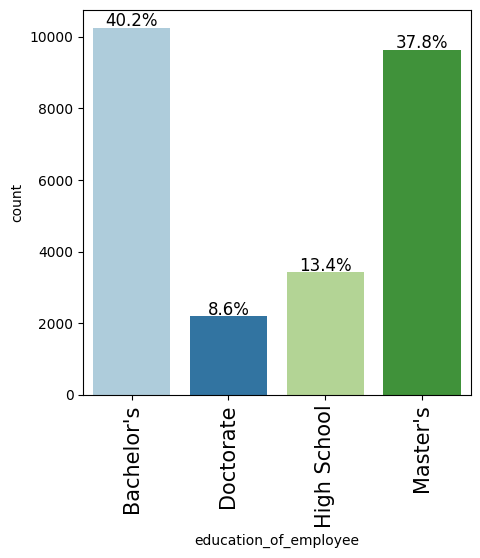

In [ ]:
labeled_barplot(data, "education_of_employee", perc=True)

**OBSERVATIONS**:
- Bachelors and Masters together constitute around 78% of the total applicants in all and Doctorate and High School constitute the remaining 22%
- There are >10k Bachelors and a little less than 10k Masters.


#### Observations on region of employment

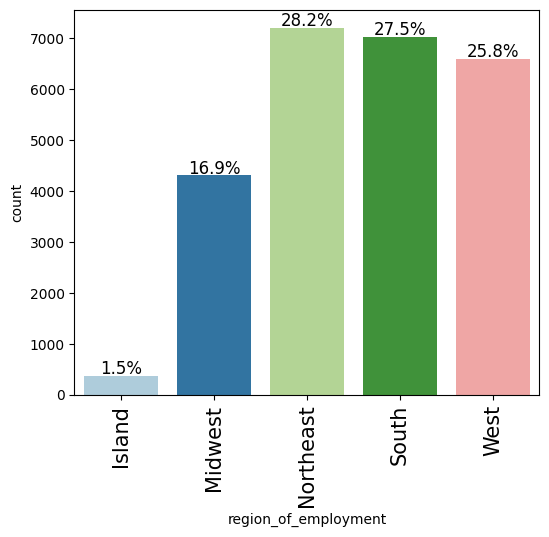

In [ ]:
labeled_barplot(data,"region_of_employment",perc=True)

**OBSERVATIONS**:
- Northeast has the highest number of applicants in the dataset ( > 7000) whereas Island has the least amount of applicants ( < 5000) which is far less than the other 4 values (Midwest, Northeat, South, West)  

#### Observations on job experience

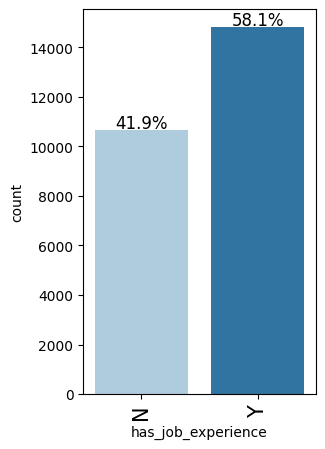

In [ ]:
labeled_barplot(data,"has_job_experience",perc=True)

**OBSERVATIONS**:
- There are around > 14k applicants with job experience and roughly 10800 applicants with no job experience

#### Observations on case status

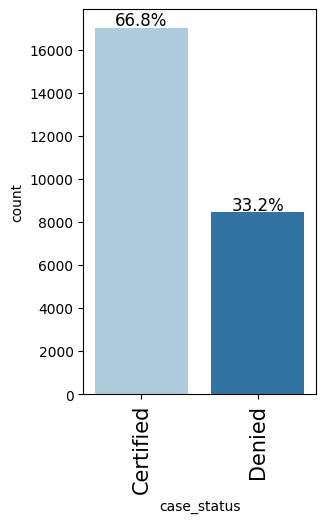

In [ ]:
labeled_barplot(data,"case_status",perc=True)

**OBSERVATIONS**:
- The number of cases Certified or approved visa status are twice that of the number of cases Denied

### Bivariate Analysis

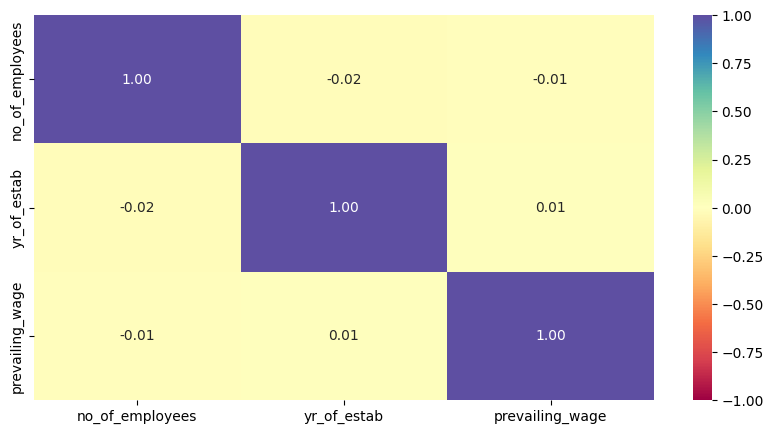

In [ ]:
cols_list = data.select_dtypes(include=np.number).columns.tolist()

plt.figure(figsize=(10, 5))
sns.heatmap(
    data[cols_list].corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral"
)
plt.show()

#### OBSERVATIONS:
- There is no strong correlation amongst the 3 numerical columns based on the above heatmap

**Creating functions that will help us with further analysis.**

In [ ]:
### function to plot distributions wrt target


def distribution_plot_wrt_target(data, predictor, target):

    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    target_uniq = data[target].unique()

    axs[0, 0].set_title("Distribution of target for target=" + str(target_uniq[0]))
    sns.histplot(
        data=data[data[target] == target_uniq[0]],
        x=predictor,
        kde=True,
        ax=axs[0, 0],
        color="teal",
        stat="density",
    )

    axs[0, 1].set_title("Distribution of target for target=" + str(target_uniq[1]))
    sns.histplot(
        data=data[data[target] == target_uniq[1]],
        x=predictor,
        kde=True,
        ax=axs[0, 1],
        color="orange",
        stat="density",
    )

    axs[1, 0].set_title("Boxplot w.r.t target")
    sns.boxplot(data=data, x=target, y=predictor, ax=axs[1, 0], palette="gist_rainbow")

    axs[1, 1].set_title("Boxplot (without outliers) w.r.t target")
    sns.boxplot(
        data=data,
        x=target,
        y=predictor,
        ax=axs[1, 1],
        showfliers=False,
        palette="gist_rainbow",
    )

    plt.tight_layout()
    plt.show()

In [ ]:
def stacked_barplot(data, predictor, target):
    """
    Print the category counts and plot a stacked bar chart

    data: dataframe
    predictor: independent variable
    target: target variable
    """
    count = data[predictor].nunique()
    sorter = data[target].value_counts().index[-1]
    tab1 = pd.crosstab(data[predictor], data[target], margins=True).sort_values(
        by=sorter, ascending=False
    )
    print(tab1)
    print("-" * 120)
    tab = pd.crosstab(data[predictor], data[target], normalize="index").sort_values(
        by=sorter, ascending=False
    )
    tab.plot(kind="bar", stacked=True, figsize=(count + 5, 5))
    plt.legend(
        loc="lower left", frameon=False,
    )
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

#### Does higher education increase the chances of visa certification for well-paid jobs abroad?

case_status            Certified  Denied    All
education_of_employee                          
All                        17018    8462  25480
Bachelor's                  6367    3867  10234
High School                 1164    2256   3420
Master's                    7575    2059   9634
Doctorate                   1912     280   2192
------------------------------------------------------------------------------------------------------------------------


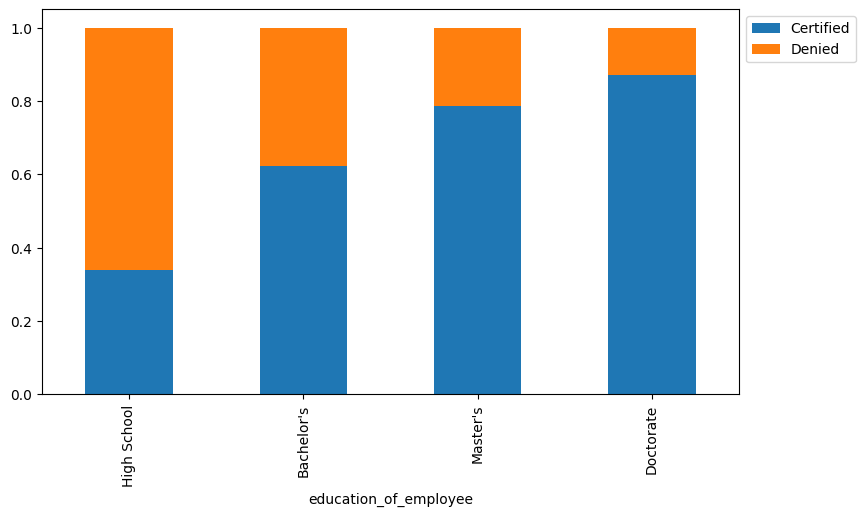

In [ ]:
stacked_barplot(data, "education_of_employee", "case_status")

**OBSERVATIONS**:
- The probability of getting 'Certified' case_status (our target variable) with a Degree of Bachelor's, Master's or Doctorate  is higher.
- Based on the number of applications too, we have a significant proportion of Bachelor's candidates in our dataset.
- Based on the numbers and the graph, Yes, the higher the education, the greater are the chances of visa certification for well-paid jobs abroad

#### How does visa status vary across different continents?

case_status    Certified  Denied    All
continent                              
All                17018    8462  25480
Asia               11012    5849  16861
North America       2037    1255   3292
Europe              2957     775   3732
South America        493     359    852
Africa               397     154    551
Oceania              122      70    192
------------------------------------------------------------------------------------------------------------------------


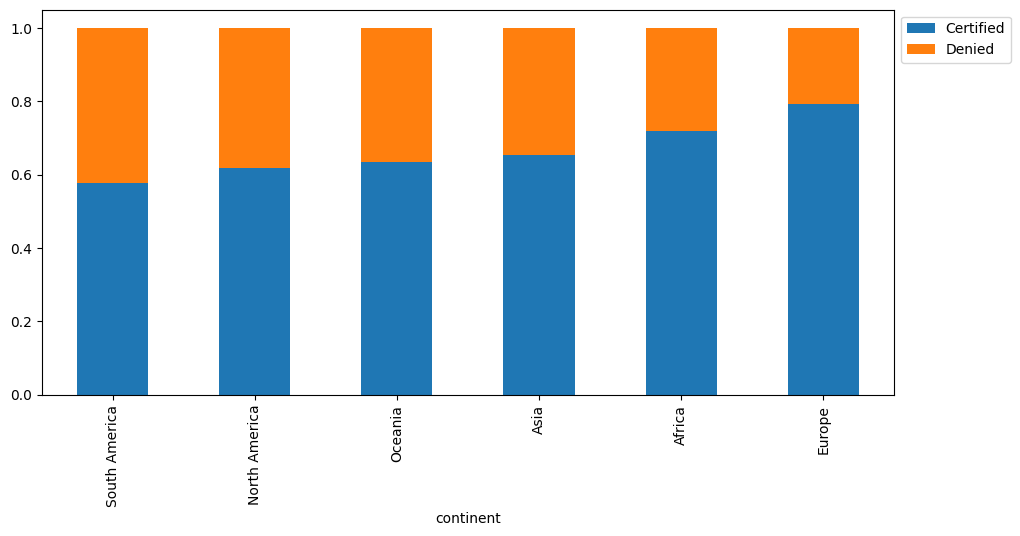

In [ ]:
stacked_barplot(data, "continent", "case_status")

**OBSERVATIONS**:
- Europe has the highest proportion of Visa Certifications as compared to Denials. Whereas South America has the lowest proportion of Visa Certifications as compared to Denials.
- However, The dataset is significantly imbalanced in terms that the number of applications from Asia are significantly high(16861) which makes up about 66% of the total dataset.

#### Does having prior work experience influence the chances of visa certification for career opportunities abroad?

has_job_experience      N      Y    All
case_status                            
All                 10678  14802  25480
Certified            5994  11024  17018
Denied               4684   3778   8462
------------------------------------------------------------------------------------------------------------------------


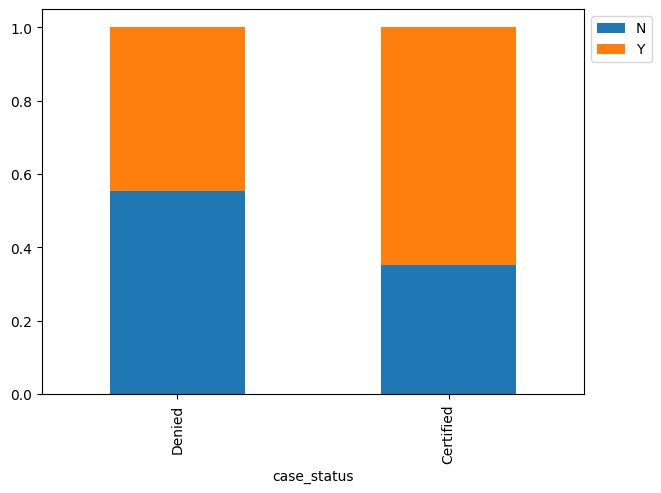

In [ ]:
stacked_barplot(data, "case_status", "has_job_experience")

**OBSERVATIONS**:
- Without job experience, the probability of getting Certified status is less than that if you have a certified status.
 - Yes, prior work experience influences the chances of visa certification positively

#### Is the prevailing wage consistent across all regions of the US?

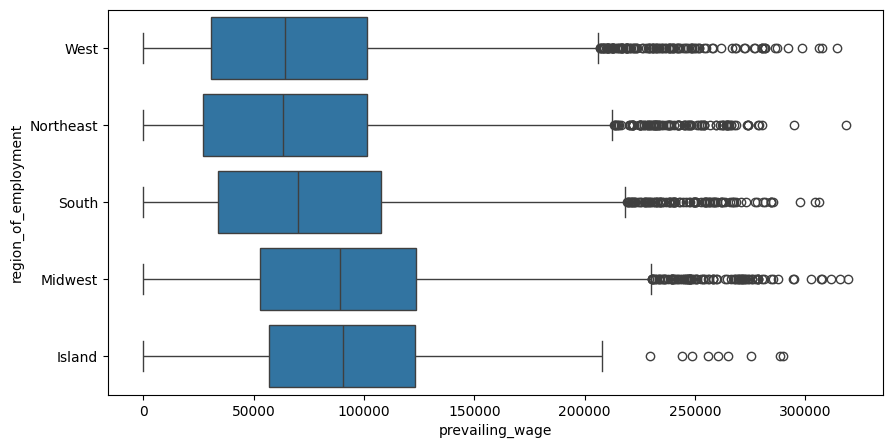

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=data, x="prevailing_wage", y="region_of_employment")
plt.show()

**OBSERVATIONS**:
- Yes, the prevailing_wage is relatively consistent across all regions, even though there are outliers for each region.
- There is more data for South, Northeast, West,  Midwest regions as compared to Island region.

#### Does visa status vary with changes in the prevailing wage set to protect both local talent and foreign workers?

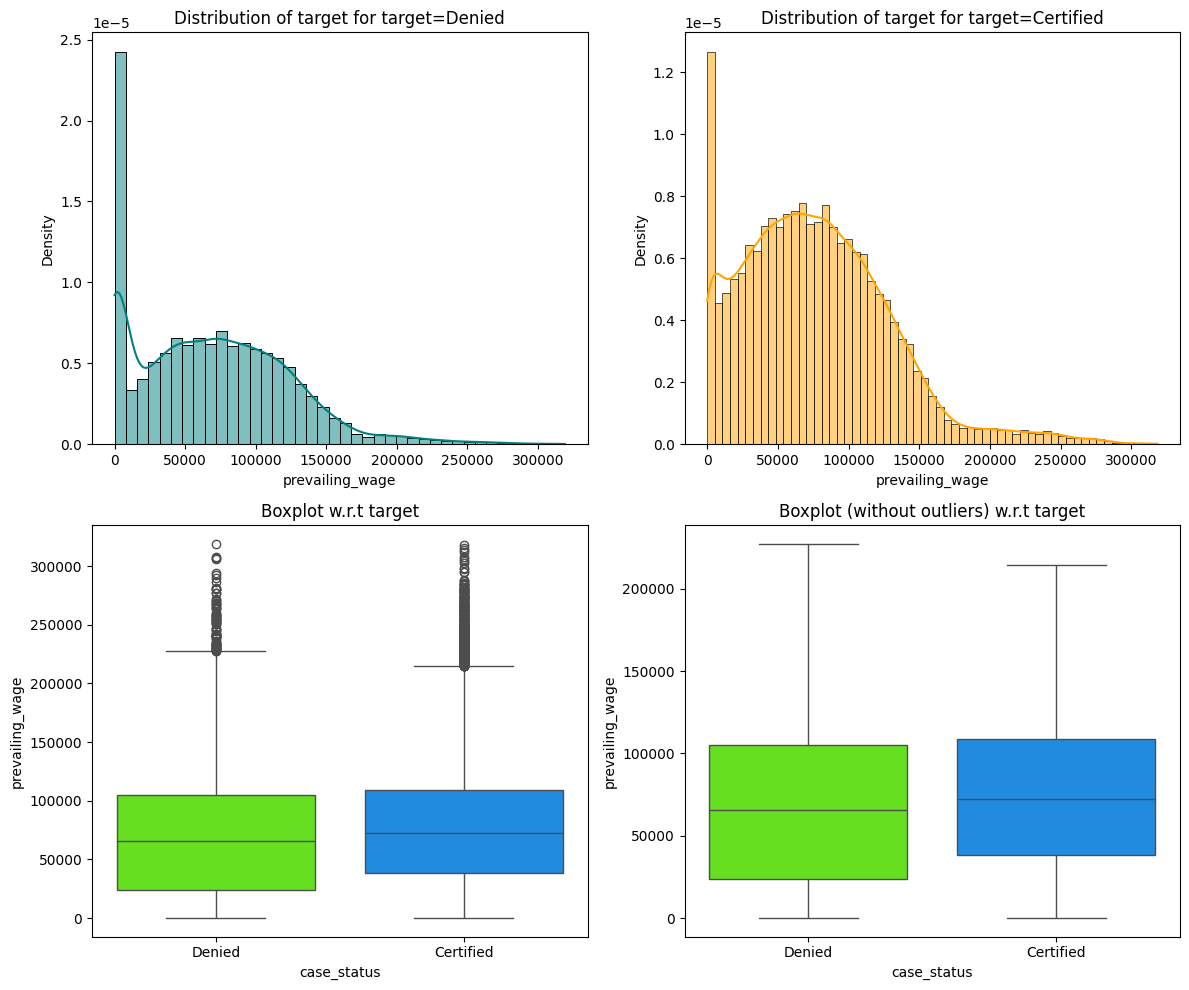

In [ ]:
distribution_plot_wrt_target(data,"prevailing_wage","case_status")


**OBSERVATIONS**:
- The distribution of dataset is highly right skewed.
- The median of the Denied cases is slightly less than that of Approved Visa applications, however there is not a big difference in the overall graph.
- Given that, there is no significant insight into if the case_status is denied or certified based on the graphs above

#### Does the unit of prevailing wage (Hourly, Weekly, etc.) have any impact on the likelihood of visa application certification?

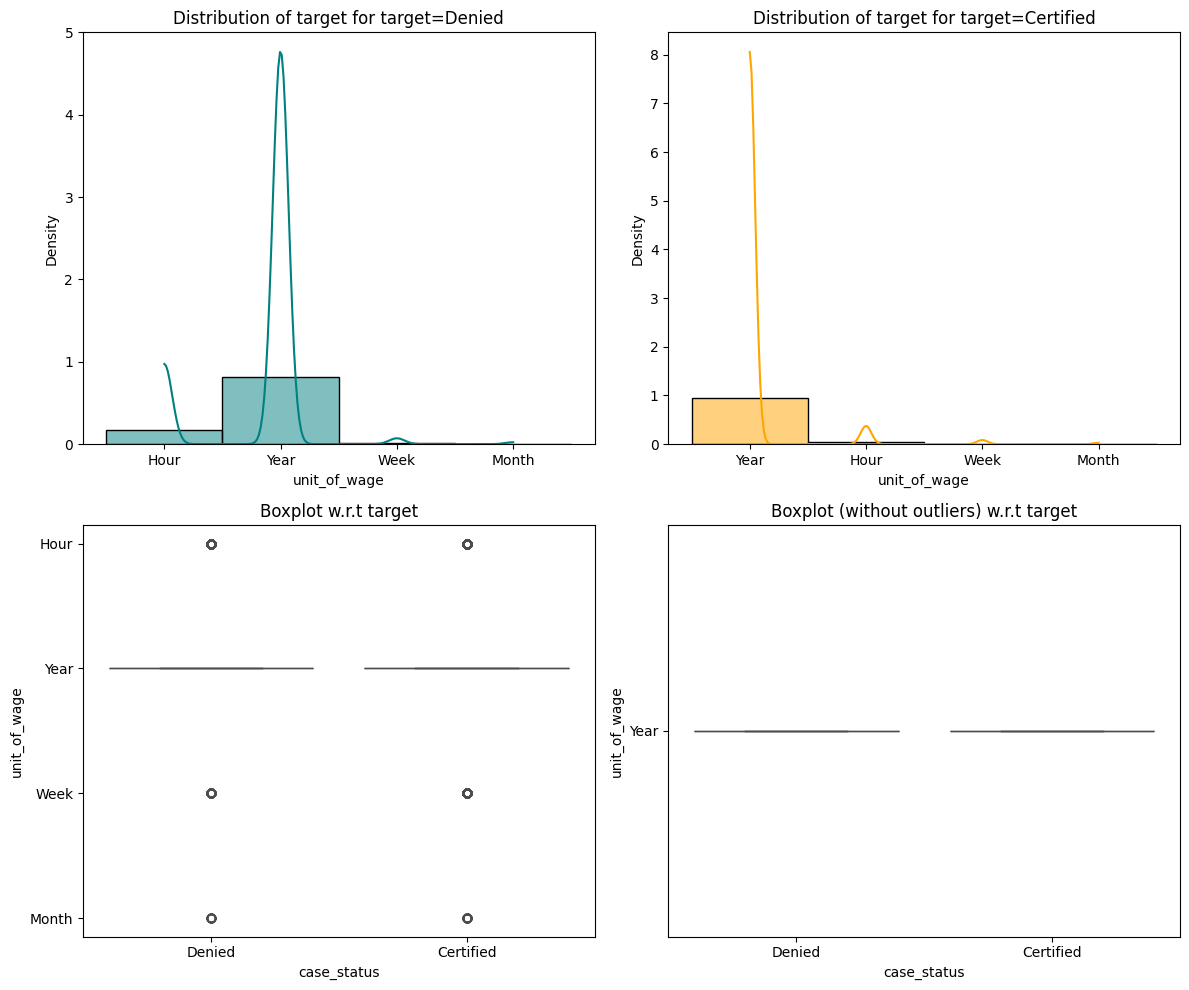

In [ ]:
distribution_plot_wrt_target(data,"unit_of_wage","case_status")

**OBSERVATIONS**:
- It does not seem like the unit_of_wage has an impact of likelihood of visa application certification.
- This makes logical sense too, as this column might be significant when combined with prevailing_wage.

## Data Pre-processing

### Outlier Check

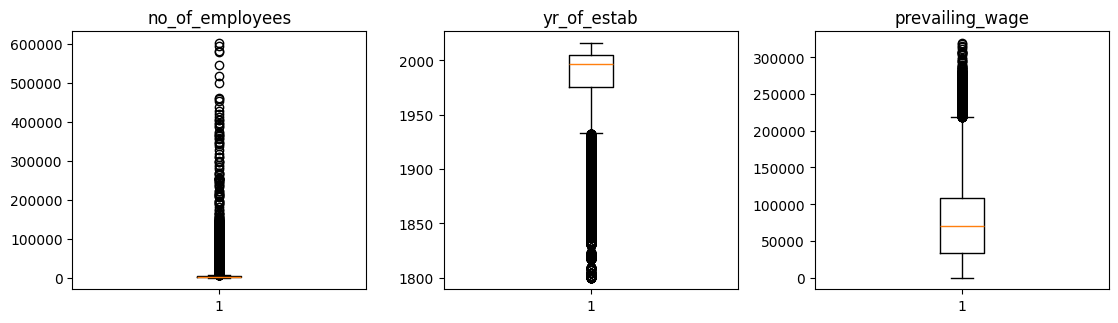

In [ ]:
# outlier detection using boxplot
numeric_columns = data.select_dtypes(include=np.number).columns.tolist()


plt.figure(figsize=(15, 12))

for i, variable in enumerate(numeric_columns):
    plt.subplot(4, 4, i + 1)
    plt.boxplot(data[variable], whis=1.5)
    plt.tight_layout()
    plt.title(variable)

plt.show()

**OBSERVATIONS**:
- All 3 numerical columns: no_of_employees, yr_of_estab, prevailing_wage (excluding case_status as it is target variable) have significant number of outliers.
- Hence, by eliminating or treating them, we would disregard important data from model building.
- Hence, we would not be doing any outlier treatment

### Data Preparation for modeling

#### Label encoding

In [ ]:
replaceStruct = {
    "has_job_experience": {"Y": 1, "N": 0},
    "requires_job_training": {"Y": 1, "N": 0},
    "full_time_position": {"Y": 1, "N": 0}
}
data = data.replace(replaceStruct)

In [ ]:
data.head()

,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,Asia,High School,0,0,14513,2007,West,592.2029,Hour,1,Denied
1,Asia,Master's,1,0,2412,2002,Northeast,83425.6500,Year,1,Certified
2,Asia,Bachelor's,0,1,44444,2008,West,122996.8600,Year,1,Denied
3,Asia,Bachelor's,0,0,98,1897,West,83434.0300,Year,1,Denied
4,Africa,Master's,1,0,1082,2005,South,149907.3900,Year,1,Certified


Observations: Replaced columns with Y/N data to int : 1/0 values as label encoding

#### Standardize prevailing_wage and drop unit_of_wage

In [ ]:
def standardize_prevailing_wage_amount(prevailing_wage, unit_of_wage):
  if unit_of_wage == 'Year':
    return prevailing_wage
  elif unit_of_wage == 'Hour':
    return prevailing_wage * 40 * 52
  elif unit_of_wage == 'Week':
    return prevailing_wage * 52
  elif unit_of_wage == 'Month':
    return prevailing_wage * 12
  else:
    return prevailing_wage


In [ ]:
data['prevailing_wage'] = data.apply(lambda x: standardize_prevailing_wage_amount(x['prevailing_wage'], x['unit_of_wage']), axis=1)

In [ ]:
data.drop(['unit_of_wage'],axis=1,inplace=True)

In [ ]:
data.head()

,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,full_time_position,case_status
0,Asia,High School,0,0,14513,2007,West,1231782.032,1,Denied
1,Asia,Master's,1,0,2412,2002,Northeast,83425.650,1,Certified
2,Asia,Bachelor's,0,1,44444,2008,West,122996.860,1,Denied
3,Asia,Bachelor's,0,0,98,1897,West,83434.030,1,Denied
4,Africa,Master's,1,0,1082,2005,South,149907.390,1,Certified


Observations:
- To reduce dimensions, combined: prevailing_wage and unit_of_wage to 1 column where the unit_of_wage is always Year based on the standard metrics like: 40 hr work week, 12 month a year, 52 weeks a year.
- Year is chosen to be the standard value since most of the data in prevailing_wage is of Year.
- Post that, we do not need the unit_of_wage, so dropping that column

#### Year of establishment to Company Age

In [ ]:
from datetime import date
data['company_age'] = date.today().year - data['yr_of_estab']
data.drop(['yr_of_estab'],axis=1,inplace=True)

In [ ]:
data.head()

,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,region_of_employment,prevailing_wage,full_time_position,case_status,company_age
0,Asia,High School,0,0,14513,West,1231782.032,1,Denied,18
1,Asia,Master's,1,0,2412,Northeast,83425.650,1,Certified,23
2,Asia,Bachelor's,0,1,44444,West,122996.860,1,Denied,17
3,Asia,Bachelor's,0,0,98,West,83434.030,1,Denied,128
4,Africa,Master's,1,0,1082,South,149907.390,1,Certified,20


Observations:
- Converted 'yr_of_estab' of company to 'company_age'. This is not necessary.

### Splitting the data into training, validation and test set

In [ ]:
data["case_status"] = data["case_status"].apply(lambda x: 1 if x == "Certified" else 0)

X = data.drop(['case_status'],axis=1)
y = data["case_status"]


X = pd.get_dummies(X,drop_first=True)

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.3, random_state=1, stratify=y
)


X_val,X_test,y_val,y_test = train_test_split(
    X_val,y_val,test_size=0.1,random_state=1,stratify=y_val
)

**OBSERVATIONS**:
- We had already dropped case_id earlier.
- We performed label encoding of case_status using lambda function
- We now drop case_status from X as that is target variable y
- Split for Train-Val is 70:30
- Further split of Val into final Validation and test in the ratio: 90:10
- Since the data is not even for case_status so we use stratify=y to evenly distribute in our splits.

In [ ]:
print("Shape of Training set : ", X_train.shape)
print("Shape of Validation set : ", X_val.shape)
print("Shape of test set : ", X_test.shape)
print("Percentage of classes in training set:")
print(y_train.value_counts(normalize=True))
print("Percentage of classes in validation set:")
print(y_val.value_counts(normalize=True))
print("Percentage of classes in test set:")
print(y_test.value_counts(normalize=True))

Shape of Training set :  (17836, 18)
Shape of Validation set :  (6879, 18)
Shape of test set :  (765, 18)
Percentage of classes in training set:
case_status
1    0.667919
0    0.332081
Name: proportion, dtype: float64
Percentage of classes in validation set:
case_status
1    0.66783
0    0.33217
Name: proportion, dtype: float64
Percentage of classes in test set:
case_status
1    0.667974
0    0.332026
Name: proportion, dtype: float64


**OBSERVATIONS**:
- Our final set has 18 columns/features to evaluate on
- Records of Training set: 17836, Validation set: 6879, Testing set: 765

## Model Building

### Model Evaluation Criterion

- Choose the primary metric to evaluate the model on
- Elaborate on the rationale behind choosing the metric

First, let's create functions to calculate different metrics and confusion matrix so that we don't have to use the same code repeatedly for each model.
* The `model_performance_classification_sklearn` function will be used to check the model performance of models.
* The `confusion_matrix_sklearn` function will be used to plot the confusion matrix.

In [ ]:
# defining a function to compute different metrics to check performance of a classification model built using sklearn


def model_performance_classification_sklearn(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred)  # to compute Recall
    precision = precision_score(target, pred)  # to compute Precision
    f1 = f1_score(target, pred)  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1,},
        index=[0],
    )

    return df_perf

In [ ]:
def confusion_matrix_sklearn(model, predictors, target):
    """
    To plot the confusion_matrix with percentages

    model: classifier
    predictors: independent variables
    target: dependent variable
    """
    y_pred = model.predict(predictors)
    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")

#### Defining scorer to be used for cross-validation and hyperparameter tuning

In [ ]:
scorer = metrics.make_scorer(metrics.f1_score)

**OBSERVATIONS**:
- I want to optimize for both :
  - precision score (minimize: False Positive = minimize: approving someone who should be denied) and
  - recall score (minimize: False Negative = minimize: denying who should be approved)
- Also the dataset has uneven distribution of Approved/Denied cases
- Considering both of these reasons, I would opt for f1-score

**We are now done with pre-processing and evaluation criterion, so let's start building the model.**

### Model building with Original data

In [ ]:
models = []  # Empty list to store all the models

# Appending models into the list
models.append(("Bagging", BaggingClassifier(random_state=1)))
models.append(("Random forest", RandomForestClassifier(random_state=1)))
models.append(("GBM", GradientBoostingClassifier(random_state=1)))
models.append(("Adaboost", AdaBoostClassifier(random_state=1)))
models.append(("Xgboost", XGBClassifier(random_state=1, eval_metric="logloss")))
models.append(("dtree", DecisionTreeClassifier(random_state=1)))

results1 = []  # Empty list to store all model's CV scores
names = []  # Empty list to store name of the models


# loop through all models to get the mean cross validated score
print("\n" "Cross-Validation performance on training dataset:" "\n")
for name, model in models:
    kfold = StratifiedKFold(
        n_splits=10, shuffle=True, random_state=1
    )
    cv_result = cross_val_score(
        estimator=model, X=X_train, y=y_train, scoring = scorer,cv=kfold
    )
    results1.append(cv_result)
    names.append(name)
    print("{}: {}".format(name, cv_result.mean()))

print("\n" "Validation Performance:" "\n")
for name, model in models:
    model.fit(X_train,y_train)
    scores = f1_score(y_val, model.predict(X_val))
    print("{}: {}".format(name, scores))


Cross-Validation performance on training dataset:

Bagging: 0.7730250568102608
Random forest: 0.8017622159632474
GBM: 0.8200038675435504
Adaboost: 0.8168995938960878
Xgboost: 0.8074136314105864
dtree: 0.7395417712705374

Validation Performance:

Bagging: 0.7635688544283062
Random forest: 0.7954474261250913
GBM: 0.8139201637666326
Adaboost: 0.8112168252378568
Xgboost: 0.8040387389243767
dtree: 0.7362901463840944


**OBSERVATIONS**:


---

- We are going to use all the different classifiers we explored for the ML and Advanced ML section of the course: Bagging, Random Forest (RF) , Gradient Boost(GBM), AdaBoost, XgBoost, DecisionTree.
- I ran the above code with a few different parameters. Finally choosing the evaluations as mentioned below.
- I also ran the code for recall_score, which gives better result than f1_score, but f1_score is better for our usecase so planning to select that.

---

- Evaluation of the models is as follows:

- Cross-Validation performance on training dataset:

  - Bagging: 0.7730250568102608
  - Random forest: 0.8017622159632474
  - GBM: 0.8200038675435504
  - Adaboost: 0.8168995938960878
  - Xgboost: 0.8074136314105864
  - dtree: 0.7395417712705374

- Validation Performance:

  - Bagging: 0.7635688544283062
  - Random forest: 0.7954474261250913
  - GBM: 0.8139201637666326
  - Adaboost: 0.8112168252378568
  - Xgboost: 0.8040387389243767
  - dtree: 0.7362901463840944


---

- The performance of all models drops very slightly in the validation set, but overall the models are generalizing well.

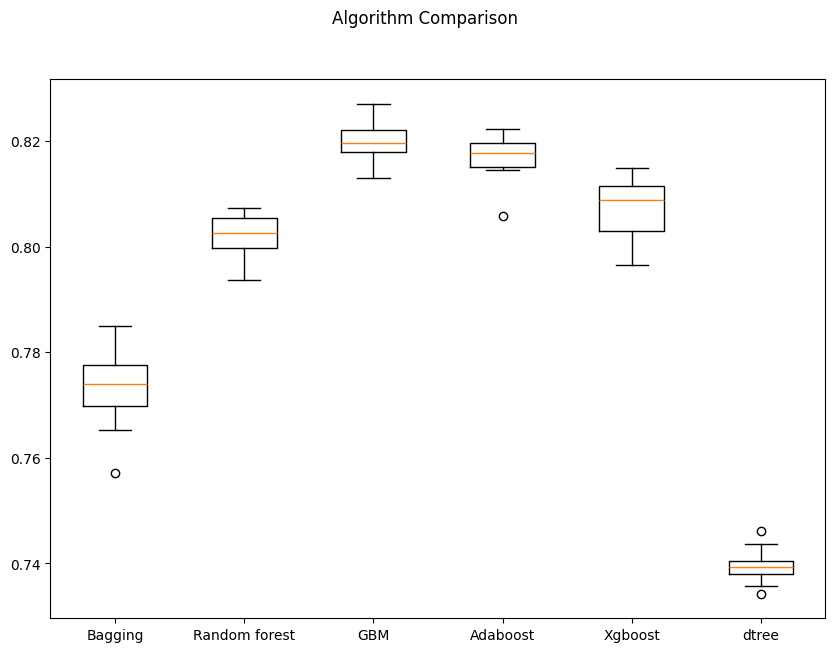

In [ ]:
# Plotting boxplots for CV scores of all models defined above
fig = plt.figure(figsize=(10, 7))

fig.suptitle("Algorithm Comparison")
ax = fig.add_subplot(111)

plt.boxplot(results1)
ax.set_xticklabels(names)

plt.show()

**OBSERVATIONS**:
- GBM and AdaBoost give the optimal performance. dtree has the least optimal.
- Adaboost has an outlier but other than that the performance is good, since less variance.
- For **hyperparameter tuning**, I will shortlist **GBM** and **Adaboost** for **original** data based on the model performance on f1_scores and evaluation on boxplots



### Model Building with Oversampled data

In [ ]:
print("Before OverSampling, counts of label '1': {}".format(sum(y_train == 1)))
print("Before OverSampling, counts of label '0': {} \n".format(sum(y_train == 0)))

# Synthetic Minority Over Sampling Technique
sm = SMOTE(sampling_strategy=1, k_neighbors=10, random_state=1)
X_train_over, y_train_over = sm.fit_resample(X_train, y_train)


print("After OverSampling, counts of label '1': {}".format(sum(y_train_over == 1)))
print("After OverSampling, counts of label '0': {} \n".format(sum(y_train_over == 0)))


print("After OverSampling, the shape of train_X: {}".format(X_train_over.shape))
print("After OverSampling, the shape of train_y: {} \n".format(y_train_over.shape))

Before OverSampling, counts of label '1': 11913
Before OverSampling, counts of label '0': 5923 

After OverSampling, counts of label '1': 11913
After OverSampling, counts of label '0': 11913 

After OverSampling, the shape of train_X: (23826, 18)
After OverSampling, the shape of train_y: (23826,) 



**OBSERVATIONS**:
- We used the SMOTE technique to oversample the data.
- I used k_neighbours=10 instead of 5 because based on the outlier checks and general understanding of the data from the uni and bi variant analysis, the data is not closely clustered. So I wanted to generalize well
- The counts of visa denied ('0') were less so by oversampling we increased that count from 5923 to 11913 to match the number of cases of visa Certified ('1')
- Since we are introducing synthetic samples, the rows in training data is: 23826 (which is double of: 11913 which is the count's of '1')


In [ ]:
models = []  # Empty list to store all the models

# Appending models into the list
models.append(("Bagging", BaggingClassifier(random_state=1)))
models.append(("Random forest", RandomForestClassifier(random_state=1)))
models.append(("GBM", GradientBoostingClassifier(random_state=1)))
models.append(("Adaboost", AdaBoostClassifier(random_state=1)))
models.append(("Xgboost", XGBClassifier(random_state=1, eval_metric="logloss")))
models.append(("dtree", DecisionTreeClassifier(random_state=1)))

results1 = []  # Empty list to store all model's CV scores
names = []  # Empty list to store name of the models


# loop through all models to get the mean cross validated score
print("\n" "Cross-Validation performance on oversampled training dataset:" "\n")
for name, model in models:
    kfold = StratifiedKFold(
        n_splits=10, shuffle=True, random_state=1
    )
    cv_result = cross_val_score(
        estimator=model, X=X_train_over, y=y_train_over,scoring = scorer, cv=kfold
    )
    results1.append(cv_result)
    names.append(name)
    print("{}: {}".format(name, cv_result.mean()))

print("\n" "Validation Performance:" "\n")
for name, model in models:
    model.fit(X_train_over,y_train_over)
    scores = f1_score(y_val, model.predict(X_val))
    print("{}: {}".format(name, scores))


Cross-Validation performance on oversampled training dataset:

Bagging: 0.7582633130045398
Random forest: 0.7964709815582638
GBM: 0.8034085101319473
Adaboost: 0.7865022983944723
Xgboost: 0.8017902590625289
dtree: 0.7283787021643164

Validation Performance:

Bagging: 0.764249279219339
Random forest: 0.7911855069392945
GBM: 0.8067368421052632
Adaboost: 0.7951781748969018
Xgboost: 0.7981940361192776
dtree: 0.7286171504248979


**OBSERVATIONS**:
- The performance of the models on oversampled data is less than that of the original data.
- Although some of these models are generalizing better than original data wherever the score on Validation set is slightly higher than that of training set (Bagging, GBM, AdaBoost, dtree)
- All f1_scores are in the range of 0.7-0.8 which is quite good.


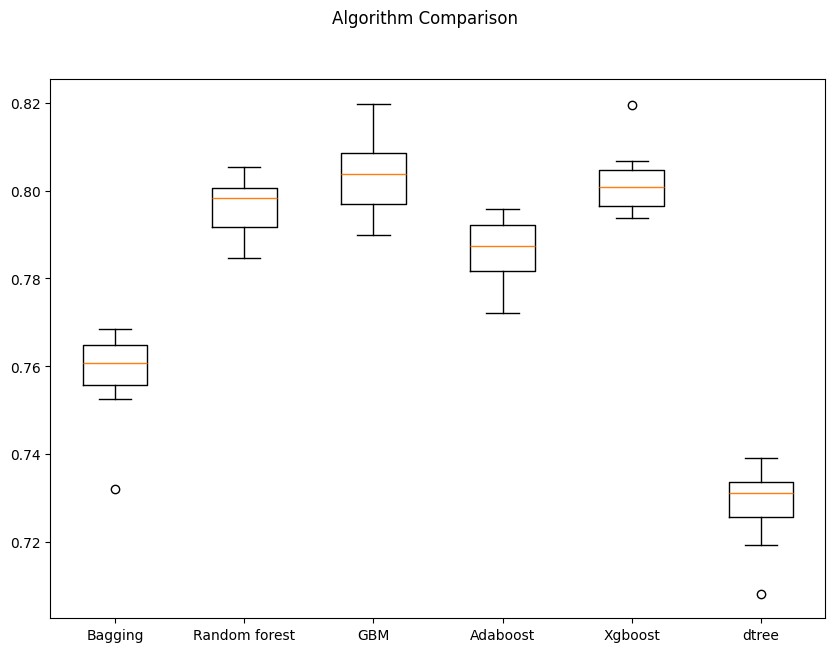

In [ ]:
# Plotting boxplots for CV scores of all models defined above
fig = plt.figure(figsize=(10, 7))

fig.suptitle("Algorithm Comparison")
ax = fig.add_subplot(111)

plt.boxplot(results1)
ax.set_xticklabels(names)

plt.show()

**OBSERVATIONS**:
- GBM model has the highest median score as compared to other models.
RandomForest, XgBoost and AdaBoost are close in performance to GBM.
- Bagging and dtree are the least optimal models
- For **hyperparameter tuning**, I will shortlist **GBM**, **XGBoost** and **Random Forest** for **oversampled** data based on the model performance on f1_scores and evaluation on boxplots


### Model Building with Undersampled data

In [ ]:
rus = RandomUnderSampler(random_state=1, sampling_strategy=1)
X_train_un, y_train_un = rus.fit_resample(X_train, y_train)


print("Before UnderSampling, counts of label '1': {}".format(sum(y_train == 1)))
print("Before UnderSampling, counts of label '0': {} \n".format(sum(y_train == 0)))


print("After UnderSampling, counts of label '1': {}".format(sum(y_train_un == 1)))
print("After UnderSampling, counts of label '0': {} \n".format(sum(y_train_un == 0)))


print("After UnderSampling, the shape of train_X: {}".format(X_train_un.shape))
print("After UnderSampling, the shape of train_y: {} \n".format(y_train_un.shape))

Before UnderSampling, counts of label '1': 11913
Before UnderSampling, counts of label '0': 5923 

After UnderSampling, counts of label '1': 5923
After UnderSampling, counts of label '0': 5923 

After UnderSampling, the shape of train_X: (11846, 18)
After UnderSampling, the shape of train_y: (11846,) 



**OBSERVATIONS**:
- We now use undersampling to reduce the Visa Certified case_status('1') to match the number of Visa Denied case_status ('0').
- We use RandomUnderSampler to do the same.
- The count of '1' and '0' cases after Undersampling is 5923.
- The total count of training data also reduces to 11846

In [ ]:
models = []  # Empty list to store all the models

# Appending models into the list
models.append(("Bagging", BaggingClassifier(random_state=1)))
models.append(("Random forest", RandomForestClassifier(random_state=1)))
models.append(("GBM", GradientBoostingClassifier(random_state=1)))
models.append(("Adaboost", AdaBoostClassifier(random_state=1)))
models.append(("Xgboost", XGBClassifier(random_state=1, eval_metric="logloss")))
models.append(("dtree", DecisionTreeClassifier(random_state=1)))

results1 = []  # Empty list to store all model's CV scores
names = []  # Empty list to store name of the models


# loop through all models to get the mean cross validated score
print("\n" "Cross-Validation performance on undersampled training dataset:" "\n")
for name, model in models:
    kfold = StratifiedKFold(
        n_splits=10, shuffle=True, random_state=1
    )
    cv_result = cross_val_score(
        estimator=model, X=X_train_un, y=y_train_un,scoring = scorer, cv=kfold,n_jobs =-1
    )
    results1.append(cv_result)
    names.append(name)
    print("{}: {}".format(name, cv_result.mean()))

print("\n" "Validation Performance:" "\n")
for name, model in models:
    model.fit(X_train_un,y_train_un)
    scores = f1_score(y_val, model.predict(X_val))
    print("{}: {}".format(name, scores))


Cross-Validation performance on undersampled training dataset:

Bagging: 0.6400931769707825
Random forest: 0.6830471488332805
GBM: 0.7097909154962853
Adaboost: 0.6924769592119823
Xgboost: 0.6876465225554875
dtree: 0.6178984343815567

Validation Performance:

Bagging: 0.6927083333333334
Random forest: 0.7283788619825838
GBM: 0.7592570961336292
Adaboost: 0.7338748208313426
Xgboost: 0.7416154936230515
dtree: 0.6790945406125166


**OBSERVATIONS**:
- The performance of all the models has reduced significantly for all the models as compared to the original as well as oversampled dataset.
- Comparing the performance of training vs validation data, all models perform well as the f1_score increase by ~0.3-0.5 for all models.

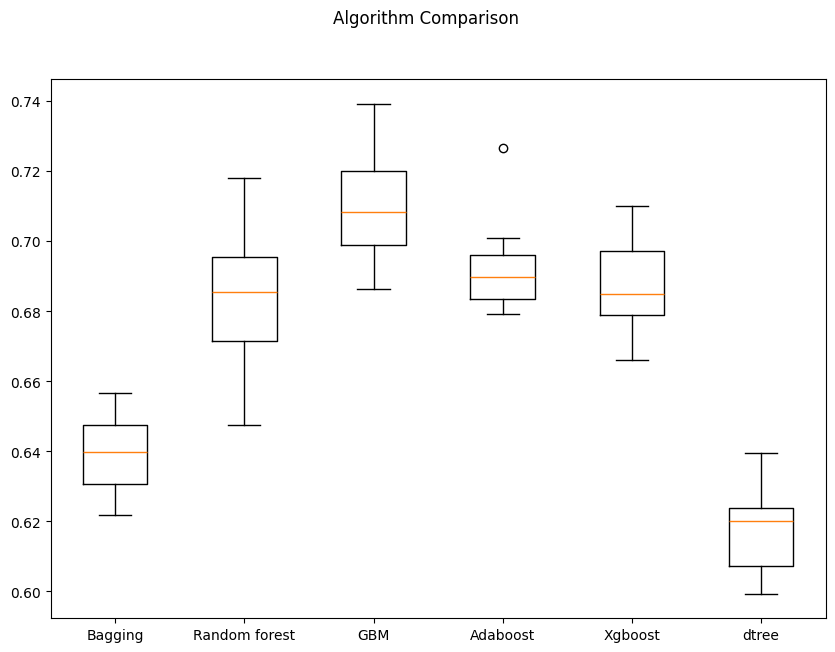

In [ ]:
# Plotting boxplots for CV scores of all models defined above
fig = plt.figure(figsize=(10, 7))

fig.suptitle("Algorithm Comparison")
ax = fig.add_subplot(111)

plt.boxplot(results1)
ax.set_xticklabels(names)

plt.show()

**OBSERVATIONS**:
- GBM shows the best performance for undersampling-treated data as compared to other models for undersampling
- The performance all models has decreased
- The IQR is larger for these models as compared to original and oversampled. This also signifies that the models from Undersampled data are less reliable.
- For **hyperparameter tuning**, I will still choose the **AdaBoost** with **Undersampled** data model for comparison as its IQR is the least and based on f1_scores

## Hyperparameter Tuning

### Tuning AdaBoost using Original data

**Best practices for hyperparameter tuning in AdaBoost:**

`n_estimators`:

- Start with a specific number (50 is used in general) and increase in steps: 50, 75, 85, 100

- Use fewer estimators (e.g., 50 to 100) if using complex base learners (like deeper decision trees)

- Use more estimators (e.g., 100 to 150) when learning rate is low (e.g., 0.1 or lower)

- Avoid very high values unless performance keeps improving on validation

`learning_rate`:

- Common values to try: 1.0, 0.5, 0.1, 0.01

- Use 1.0 for faster training, suitable for fewer estimators

- Use 0.1 or 0.01 when using more estimators to improve generalization

- Avoid very small values (< 0.01) unless you plan to use many estimators (e.g., >500) and have sufficient data


---

In [ ]:
%%time

# defining model
model = AdaBoostClassifier(random_state=1)

# Parameter grid to pass in RandomSearchCV
param_grid = {
    "n_estimators": np.arange(10,71,20),
    "learning_rate": [1.0,0.5,0.1,0.01],
    "estimator": [DecisionTreeClassifier(max_depth=1, random_state=1),
                  DecisionTreeClassifier(max_depth=2, random_state=1),
                  DecisionTreeClassifier(max_depth=3, random_state=1),
    ]
}

#Calling RandomizedSearchCV
randomized_cv = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=50,
    n_jobs=-1,
    scoring=scorer,
    cv=5,
    random_state=1
)

#Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train,y_train)

CPU times: user 2.12 s, sys: 290 ms, total: 2.41 s
Wall time: 2min 58s


RandomizedSearchCV(cv=5, estimator=AdaBoostClassifier(random_state=1),
                   n_iter=50, n_jobs=-1,
                   param_distributions={'estimator': [DecisionTreeClassifier(max_depth=1,
                                                                             random_state=1),
                                                      DecisionTreeClassifier(max_depth=2,
                                                                             random_state=1),
                                                      DecisionTreeClassifier(max_depth=3,
                                                                             random_state=1)],
                                        'learning_rate': [1.0, 0.5, 0.1, 0.01],
                                        'n_estimators': array([10, 30, 50, 70])},
                   random_state=1,
                   scoring=make_scorer(f1_score, response_method='predict'))

In [ ]:
print("Best parameters are {} with CV score={}:" .format(randomized_cv.best_params_,randomized_cv.best_score_))

Best parameters are {'n_estimators': np.int64(10), 'learning_rate': 0.5, 'estimator': DecisionTreeClassifier(max_depth=3, random_state=1)} with CV score=0.8205743385748198:


In [ ]:
tuned_ada = randomized_cv.best_estimator_
tuned_ada

AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3,
                                                    random_state=1),
                   learning_rate=0.5, n_estimators=np.int64(10),
                   random_state=1)

In [ ]:
tuned_ada.fit(X_train, y_train)

AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3,
                                                    random_state=1),
                   learning_rate=0.5, n_estimators=np.int64(10),
                   random_state=1)

In [ ]:
tuned_ada_train_perf = model_performance_classification_sklearn(tuned_ada, X_train, y_train)
tuned_ada_train_perf

,Accuracy,Recall,Precision,F1
0,0.74501,0.8782,0.771591,0.821451


In [ ]:
tuned_ada_val_perf = model_performance_classification_sklearn(tuned_ada,X_val,y_val)
tuned_ada_val_perf

,Accuracy,Recall,Precision,F1
0,0.735427,0.873748,0.763989,0.815191


**OBSERVATIONS**:
- The model scores are optimal
- F1 score for train and validation set is 0.821 and 0.815 respectively

### Tuning Gradient Boost using Original data

**Best practices for hyperparameter tuning in Gradient Boosting:**

`n_estimators`:

* Start with 100 (default) and increase: 100, 200, 300, 500
* Typically, higher values lead to better performance, but they also increase training time
* Use 200–500 for larger datasets or complex problems
* Monitor validation performance to avoid overfitting, as too many estimators can degrade generalization


`learning_rate`:

* Common values to try: 0.1, 0.05, 0.01, 0.005
* Use lower values (e.g., 0.01 or 0.005) if you are using many estimators (e.g., > 200)
* Higher learning rates (e.g., 0.1) can be used with fewer estimators for faster convergence
* Always balance the learning rate with `n_estimators` to prevent overfitting or underfitting


`subsample`:

* Common values: 0.7, 0.8, 0.9, 1.0
* Use a value between `0.7` and `0.9` for improved generalization by introducing randomness
* `1.0` uses the full dataset for each boosting round, potentially leading to overfitting
* Reducing `subsample` can help reduce overfitting, especially in smaller datasets


`max_features`:

* Common values: `"sqrt"`, `"log2"`, or float (e.g., `0.3`, `0.5`)
* `"sqrt"` (default) works well for classification tasks
* Lower values (e.g., `0.3`) help reduce overfitting by limiting the number of features considered at each split

---

In [ ]:
%%time

# defining model
model = GradientBoostingClassifier(random_state=1)

param_grid={
    "n_estimators": np.arange(100,400,100),
    "learning_rate": [1.0,0.5,0.1,0.01],
    "subsample":[0.8,0.9],
    "max_features":[0.3,0.5]
}

#Calling RandomizedSearchCV
randomized_cv = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=50,
    n_jobs=-1,
    scoring=scorer,
    cv=5,
    random_state=1
)

#Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train_over, y_train_over)

CPU times: user 13.3 s, sys: 850 ms, total: 14.1 s
Wall time: 14min 7s


RandomizedSearchCV(cv=5, estimator=GradientBoostingClassifier(random_state=1),
                   n_iter=50, n_jobs=-1,
                   param_distributions={'learning_rate': [1.0, 0.5, 0.1, 0.01],
                                        'max_features': [0.3, 0.5],
                                        'n_estimators': array([100, 200, 300]),
                                        'subsample': [0.8, 0.9]},
                   random_state=1,
                   scoring=make_scorer(f1_score, response_method='predict'))

In [ ]:
print("Best parameters are {} with CV score={}:" .format(randomized_cv.best_params_,randomized_cv.best_score_))

Best parameters are {'subsample': 0.8, 'n_estimators': np.int64(300), 'max_features': 0.5, 'learning_rate': 0.1} with CV score=0.8012525784360491:


In [ ]:
tuned_gbm = randomized_cv.best_estimator_
tuned_gbm

GradientBoostingClassifier(max_features=0.5, n_estimators=np.int64(300),
                           random_state=1, subsample=0.8)

In [ ]:
tuned_gbm_train_perf = model_performance_classification_sklearn(tuned_gbm, X_train, y_train)
tuned_gbm_train_perf

,Accuracy,Recall,Precision,F1
0,0.754822,0.845463,0.799111,0.821634


In [ ]:
tuned_gbm_val_perf = model_performance_classification_sklearn(tuned_gbm,X_val,y_val)
tuned_gbm_val_perf

,Accuracy,Recall,Precision,F1
0,0.72685,0.830213,0.776308,0.802356


**OBSERVATIONS**:
- The recall of this model is better than precision
- F1 score for train and validation set is 0.821 and 0.802 respectively

### Tuning Gradient Boost using Oversampled data

**Best practices for hyperparameter tuning in Gradient Boosting:**

`n_estimators`:

* Start with 100 (default) and increase: 100, 200, 300, 500
* Typically, higher values lead to better performance, but they also increase training time
* Use 200–500 for larger datasets or complex problems
* Monitor validation performance to avoid overfitting, as too many estimators can degrade generalization


`learning_rate`:

* Common values to try: 0.1, 0.05, 0.01, 0.005
* Use lower values (e.g., 0.01 or 0.005) if you are using many estimators (e.g., > 200)
* Higher learning rates (e.g., 0.1) can be used with fewer estimators for faster convergence
* Always balance the learning rate with `n_estimators` to prevent overfitting or underfitting


`subsample`:

* Common values: 0.7, 0.8, 0.9, 1.0
* Use a value between `0.7` and `0.9` for improved generalization by introducing randomness
* `1.0` uses the full dataset for each boosting round, potentially leading to overfitting
* Reducing `subsample` can help reduce overfitting, especially in smaller datasets


`max_features`:

* Common values: `"sqrt"`, `"log2"`, or float (e.g., `0.3`, `0.5`)
* `"sqrt"` (default) works well for classification tasks
* Lower values (e.g., `0.3`) help reduce overfitting by limiting the number of features considered at each split

---

In [ ]:
%%time

# defining model
model = GradientBoostingClassifier(random_state=1)


param_grid={
    "n_estimators": np.arange(100,400,100),
    "learning_rate": [1.0,0.5,0.1,0.01],
    "subsample":[0.8,0.9],
    "max_features":[0.3,0.5]
}

#Calling RandomizedSearchCV
randomized_cv = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=50,
    n_jobs=-1,
    scoring=scorer,
    cv=5,
    random_state=1
)

#Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train_over, y_train_over)

CPU times: user 11.8 s, sys: 810 ms, total: 12.6 s
Wall time: 13min 54s


RandomizedSearchCV(cv=5, estimator=GradientBoostingClassifier(random_state=1),
                   n_iter=50, n_jobs=-1,
                   param_distributions={'learning_rate': [1.0, 0.5, 0.1, 0.01],
                                        'max_features': [0.3, 0.5],
                                        'n_estimators': array([100, 200, 300]),
                                        'subsample': [0.8, 0.9]},
                   random_state=1,
                   scoring=make_scorer(f1_score, response_method='predict'))

In [ ]:
print("Best parameters are {} with CV score={}:" .format(randomized_cv.best_params_,randomized_cv.best_score_))

Best parameters are {'subsample': 0.8, 'n_estimators': np.int64(300), 'max_features': 0.5, 'learning_rate': 0.1} with CV score=0.8012525784360491:


In [ ]:
tuned_gbm_over = randomized_cv.best_estimator_
tuned_gbm_over

GradientBoostingClassifier(max_features=0.5, n_estimators=np.int64(300),
                           random_state=1, subsample=0.8)

In [ ]:
tuned_gbm_over_train_perf = model_performance_classification_sklearn(tuned_gbm_over, X_train_over, y_train_over)
tuned_gbm_over_train_perf

,Accuracy,Recall,Precision,F1
0,0.808361,0.845463,0.787059,0.815217


In [ ]:
tuned_gbm_over_val_perf = model_performance_classification_sklearn(tuned_gbm_over,X_val,y_val)
tuned_gbm_over_val_perf

,Accuracy,Recall,Precision,F1
0,0.72685,0.830213,0.776308,0.802356


**OBSERVATIONS**:
- The accuracy of this model drops ~8% in validation set
- F1 score for train and validation set is 0.815 and 0.802 respectively

### Tuning XGBoost using Oversampled data

**Best practices for hyperparameter tuning in XGBoost:**

`n_estimators`:

* Start with 50 and increase in steps: 50,75,100,125.
* Use more estimators (e.g., 150-250) when using lower learning rates
* Monitor validation performance
* High values improve learning but increase training time

`subsample`:

* Common values: 0.5, 0.7, 0.8, 1.0
* Use `0.7–0.9` to introduce randomness and reduce overfitting
* `1.0` uses the full dataset in each boosting round; may overfit on small datasets
* Values < 0.5 are rarely useful unless dataset is very large

`gamma`:

* Try values: 0 (default), 1, 3, 5, 8
* Controls minimum loss reduction needed for a split
* Higher values make the algorithm more conservative (i.e., fewer splits)
* Use values > 0 to regularize and reduce overfitting, especially on noisy data


`colsample_bytree`:

* Try values: 0.3, 0.5, 0.7, 1.0
* Fraction of features sampled per tree
* Lower values (e.g., 0.3 or 0.5) increase randomness and improve generalization
* Use `1.0` when you want all features considered for every tree


`colsample_bylevel`:

* Try values: 0.3, 0.5, 0.7, 1.0
* Fraction of features sampled at each tree level (i.e., per split depth)
* Lower values help in regularization and reducing overfitting
* Often used in combination with `colsample_bytree` for fine control over feature sampling

---

In [ ]:
%%time

# defining model
model = XGBClassifier(random_state=1,eval_metric='logloss')

## Complete the code to define the hyperparameters
param_grid={
    'n_estimators':[50, 75, 100],
    'subsample':[0.7,0.8,0.9],
    'gamma':[0,1,3],
    'colsample_bytree':[0.3,0.5],
    'colsample_bylevel':[0.3,0.7],
}

#Calling RandomizedSearchCV
randomized_cv = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=50,
    n_jobs=-1,
    scoring=scorer,
    cv=5,
    random_state=1
)

#Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train_over,y_train_over)

CPU times: user 2.41 s, sys: 232 ms, total: 2.64 s
Wall time: 1min 8s


RandomizedSearchCV(cv=5,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=False,
                                           eval_metric='logloss',
                                           feature_types=None,
                                           feature_weights=None, gamma=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_cons...
                                           min_child_weight=None, missing=nan,
                                           monotone_constraints=None,
                                           multi_strategy=None,
                                           n_estimators=None, n_jobs=None,
                                           num_parallel_tree=None, ...),
                   n_iter=50, n_jobs=-1,
                   param_distributions={'colsample_bylevel': [0.3, 0.7],
                                        'colsample_bytree': [0.3, 0.5],
                                        'gamma': [0, 1, 3],
                                        'n_estimators': [50, 75, 100],
                                        'subsample': [0.7, 0.8, 0.9]},
                   random_state=1,
                   scoring=make_scorer(f1_score, response_method='predict'))

In [ ]:
print("Best parameters are {} with CV score={}:" .format(randomized_cv.best_params_,randomized_cv.best_score_))

Best parameters are {'subsample': 0.8, 'n_estimators': 75, 'gamma': 0, 'colsample_bytree': 0.5, 'colsample_bylevel': 0.3} with CV score=0.804797228448528:


In [ ]:
tuned_xgb_over = randomized_cv.best_estimator_
tuned_xgb_over

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=0.3, colsample_bynode=None,
              colsample_bytree=0.5, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=0,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=75, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
tuned_xgb_over_train_perf = model_performance_classification_sklearn(tuned_xgb_over, X_train_over, y_train_over)
tuned_xgb_over_train_perf

,Accuracy,Recall,Precision,F1
0,0.816167,0.851926,0.795065,0.822514


In [ ]:
tuned_xgb_over_val_perf = model_performance_classification_sklearn(tuned_xgb_over,X_val,y_val)
tuned_xgb_over_val_perf

,Accuracy,Recall,Precision,F1
0,0.730048,0.831302,0.779229,0.804423


**OBSERVATIONS**:
- The evaluation metrics for all scores drops in the validation. This model is not as optimal as others.
- F1 score for train and validation set is 0.822 and 0.804 respetively

### Tuning Random forest using Oversampled data

**Best practices for hyperparameter tuning in Random Forest:**


`n_estimators`:

* Start with a specific number (50 is used in general) and increase in steps: 50, 75, 100, 125
* Higher values generally improve performance but increase training time
* Use 100-150 for large datasets or when variance is high


`min_samples_leaf`:

* Try values like: 1, 2, 4, 5, 10
* Higher values reduce model complexity and help prevent overfitting
* Use 1–2 for low-bias models, higher (like 5 or 10) for more regularized models
* Works well in noisy datasets to smooth predictions


`max_features`:

* Try values: `"sqrt"` (default for classification), `"log2"`, `None`, or float values (e.g., `0.3`, `0.5`)
* `"sqrt"` balances between diversity and performance for classification tasks
* Lower values (e.g., `0.3`) increase tree diversity, reducing overfitting
* Higher values (closer to `1.0`) may capture more interactions but risk overfitting


`max_samples` (for bootstrap sampling):

* Try float values between `0.5` to `1.0` or fixed integers
* Use `0.6–0.9` to introduce randomness and reduce overfitting
* Smaller values increase diversity between trees, improving generalization

---

In [ ]:
%%time

# defining model
model = RandomForestClassifier(random_state=1)

# Parameter grid to pass in RandomSearchCV
param_grid = {
    "n_estimators": [50, 75, 100],
    "min_samples_leaf": [1, 2, 4, 5, 10],
    "max_features": [0.3,0.5],
    "max_samples": [0.6,0.8],
}


#Calling RandomizedSearchCV
randomized_cv = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=50,
    n_jobs=-1,
    scoring=scorer,
    cv=5,
    random_state=1
)

#Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train_over,y_train_over)

CPU times: user 6.56 s, sys: 674 ms, total: 7.24 s
Wall time: 11min 3s


RandomizedSearchCV(cv=5, estimator=RandomForestClassifier(random_state=1),
                   n_iter=50, n_jobs=-1,
                   param_distributions={'max_features': [0.3, 0.5],
                                        'max_samples': [0.6, 0.8],
                                        'min_samples_leaf': [1, 2, 4, 5, 10],
                                        'n_estimators': [50, 75, 100]},
                   random_state=1,
                   scoring=make_scorer(f1_score, response_method='predict'))

In [ ]:
print("Best parameters are {} with CV score={}:" .format(randomized_cv.best_params_,randomized_cv.best_score_))

Best parameters are {'n_estimators': 75, 'min_samples_leaf': 4, 'max_samples': 0.8, 'max_features': 0.3} with CV score=0.8014990096476424:


In [ ]:
tuned_rf_over = randomized_cv.best_estimator_
tuned_rf_over

RandomForestClassifier(max_features=0.3, max_samples=0.8, min_samples_leaf=4,
                       n_estimators=75, random_state=1)

In [ ]:
tuned_rf_over.fit(X_train_over, y_train_over)

RandomForestClassifier(max_features=0.3, max_samples=0.8, min_samples_leaf=4,
                       n_estimators=75, random_state=1)

In [ ]:
tuned_rf_over_train_perf = model_performance_classification_sklearn(
    tuned_rf_over, X_train_over, y_train_over
)
tuned_rf_over_train_perf

,Accuracy,Recall,Precision,F1
0,0.856501,0.889952,0.834146,0.861146


In [ ]:
tuned_rf_over_val_perf = model_performance_classification_sklearn(tuned_rf_over,X_val,y_val)
tuned_rf_over_val_perf

,Accuracy,Recall,Precision,F1
0,0.725542,0.827819,0.776122,0.801138


**OBSERVATIONS**:
- All of the evaluation scores drop significantly in the validation set. This model is likely overfitted and not generalizing well
- F1 score for train and validation set is 0.861 and 0.801 respectively

### Tuning AdaBoost using Undersampled data

**Best practices for hyperparameter tuning in AdaBoost:**

`n_estimators`:

- Start with a specific number (50 is used in general) and increase in steps: 50, 75, 85, 100

- Use fewer estimators (e.g., 50 to 100) if using complex base learners (like deeper decision trees)

- Use more estimators (e.g., 100 to 150) when learning rate is low (e.g., 0.1 or lower)

- Avoid very high values unless performance keeps improving on validation

`learning_rate`:

- Common values to try: 1.0, 0.5, 0.1, 0.01

- Use 1.0 for faster training, suitable for fewer estimators

- Use 0.1 or 0.01 when using more estimators to improve generalization

- Avoid very small values (< 0.01) unless you plan to use many estimators (e.g., >500) and have sufficient data


---

In [ ]:
%%time

# defining model
model = AdaBoostClassifier(random_state=1)

# Parameter grid to pass in RandomSearchCV
param_grid = {
    "n_estimators": [50, 75, 100],
    "learning_rate": [1.0,0.5,0.1,0.01],
    "estimator": [DecisionTreeClassifier(max_depth=1, random_state=1), DecisionTreeClassifier(max_depth=2, random_state=1), DecisionTreeClassifier(max_depth=3, random_state=1),
    ]
}

#Calling RandomizedSearchCV
randomized_cv = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=50,
    n_jobs=-1,
    scoring=scorer,
    cv=5,
    random_state=1
)

#Fitting parameters in RandomizedSearchCV
randomized_cv.fit(X_train_un,y_train_un)

CPU times: user 2.89 s, sys: 237 ms, total: 3.13 s
Wall time: 3min 15s


RandomizedSearchCV(cv=5, estimator=AdaBoostClassifier(random_state=1),
                   n_iter=50, n_jobs=-1,
                   param_distributions={'estimator': [DecisionTreeClassifier(max_depth=1,
                                                                             random_state=1),
                                                      DecisionTreeClassifier(max_depth=2,
                                                                             random_state=1),
                                                      DecisionTreeClassifier(max_depth=3,
                                                                             random_state=1)],
                                        'learning_rate': [1.0, 0.5, 0.1, 0.01],
                                        'n_estimators': [50, 75, 100]},
                   random_state=1,
                   scoring=make_scorer(f1_score, response_method='predict'))

In [ ]:
print("Best parameters are {} with CV score={}:" .format(randomized_cv.best_params_,randomized_cv.best_score_))

Best parameters are {'n_estimators': 50, 'learning_rate': 0.1, 'estimator': DecisionTreeClassifier(max_depth=2, random_state=1)} with CV score=0.7107778661988284:


In [ ]:
tuned_ada_un = randomized_cv.best_estimator_
tuned_ada_un

AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2,
                                                    random_state=1),
                   learning_rate=0.1, random_state=1)

In [ ]:
tuned_ada_un.fit(X_train_un, y_train_un)

AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2,
                                                    random_state=1),
                   learning_rate=0.1, random_state=1)

In [ ]:
tuned_ada_un_train_perf = model_performance_classification_sklearn(tuned_ada_un, X_train, y_train)
tuned_ada_un_train_perf

,Accuracy,Recall,Precision,F1
0,0.719612,0.751532,0.814353,0.781682


In [ ]:
tuned_ada_un_val_perf = model_performance_classification_sklearn(tuned_ada_un,X_val,y_val)
tuned_ada_un_val_perf

,Accuracy,Recall,Precision,F1
0,0.711586,0.750109,0.804764,0.776476


**OBSERVATIONS**:
- The evaluation scores for both training and validation sets are poor as compared to the previous models.
- F1 score for train and validation set is 0.781 and 0.776 respectively

## Model Performance Summary and Final Model Selection

In [ ]:
# training performance comparison

models_train_comp_df = pd.concat(
    [
        tuned_gbm_train_perf.T,
        tuned_ada_train_perf.T,
        tuned_gbm_over_train_perf.T,
        tuned_rf_over_train_perf.T,
        tuned_xgb_over_train_perf.T,
        tuned_ada_un_train_perf.T,
    ],
    axis=1,
)
models_train_comp_df.columns = [
    "GradientBoost | Original",
    "AdaBoost | Original",
    "GradientBoost | Oversampled",
    "RandomForest | Oversampled",
    "XGBoost | Oversampled",
    "AdaBoost | Undersampled",
]
print("Training performance comparison:")
models_train_comp_df

Training performance comparison:


,GradientBoost | Original,AdaBoost | Original,GradientBoost | Oversampled,RandomForest | Oversampled,XGBoost | Oversampled,AdaBoost | Undersampled
Accuracy,0.754822,0.745010,0.808361,0.856501,0.816167,0.719612
Recall,0.845463,0.878200,0.845463,0.889952,0.851926,0.751532
Precision,0.799111,0.771591,0.787059,0.834146,0.795065,0.814353
F1,0.821634,0.821451,0.815217,0.861146,0.822514,0.781682


**OBSERVATIONS**:

Among the 6 models,
- RandomForest with oversampled data has the most optimal scores with F1_score of 0.861 on training data.
- Other well performing models are: Gradient Boost and AdaBoost on original data and XGBoost on oversampled data

In [ ]:
# validation performance comparison

models_val_comp_df = pd.concat(
    [
        tuned_gbm_val_perf.T,
        tuned_ada_val_perf.T,
        tuned_gbm_over_val_perf.T,
        tuned_rf_over_val_perf.T,
        tuned_xgb_over_val_perf.T,
        tuned_ada_un_val_perf.T,
    ],
    axis=1,
)
models_val_comp_df.columns = [
    "GradientBoost | Original",
    "AdaBoost | Original",
    "GradientBoost | Oversampled",
    "RandomForest | Oversampled",
    "XGBoost | Oversampled",
    "AdaBoost | Undersampled",
]
print("Validation performance comparison:")
models_val_comp_df

Validation performance comparison:


,GradientBoost | Original,AdaBoost | Original,GradientBoost | Oversampled,RandomForest | Oversampled,XGBoost | Oversampled,AdaBoost | Undersampled
Accuracy,0.726850,0.735427,0.726850,0.725542,0.730048,0.711586
Recall,0.830213,0.873748,0.830213,0.827819,0.831302,0.750109
Precision,0.776308,0.763989,0.776308,0.776122,0.779229,0.804764
F1,0.802356,0.815191,0.802356,0.801138,0.804423,0.776476


**OBSERVATIONS** :

Among the 6 models, after comparing the training and validation performance,
- RandomForest with oversampled data model's accuracy and Precision decreases significantly in validation. Hence it is overfitting and not an optimal model to choose.
- Among the other well performing models : Gradient Boost and AdaBoost on original data and XGBoost on oversampled data, it is clear that **AdaBoost with original data is the best performing model** with less variance in training and testing performance as well as the highest **F1_score** on validation of: **0.815**

In [ ]:
final_model = tuned_ada

**OBSERVATIONS**:
Final model selected is AdaBoost on original data which is tuned_ada

In [ ]:
test = model_performance_classification_sklearn(final_model, X_test, y_test)
test

,Accuracy,Recall,Precision,F1
0,0.755556,0.900196,0.771812,0.831075


**OBSERVATIONS**:
- Now that we have our model ready, we tested it on test data and that performed even better with :
- Accuracy: 0.75 | Recall: 0.9 | Precision : 0.77 and F1 Score: 0.83!!

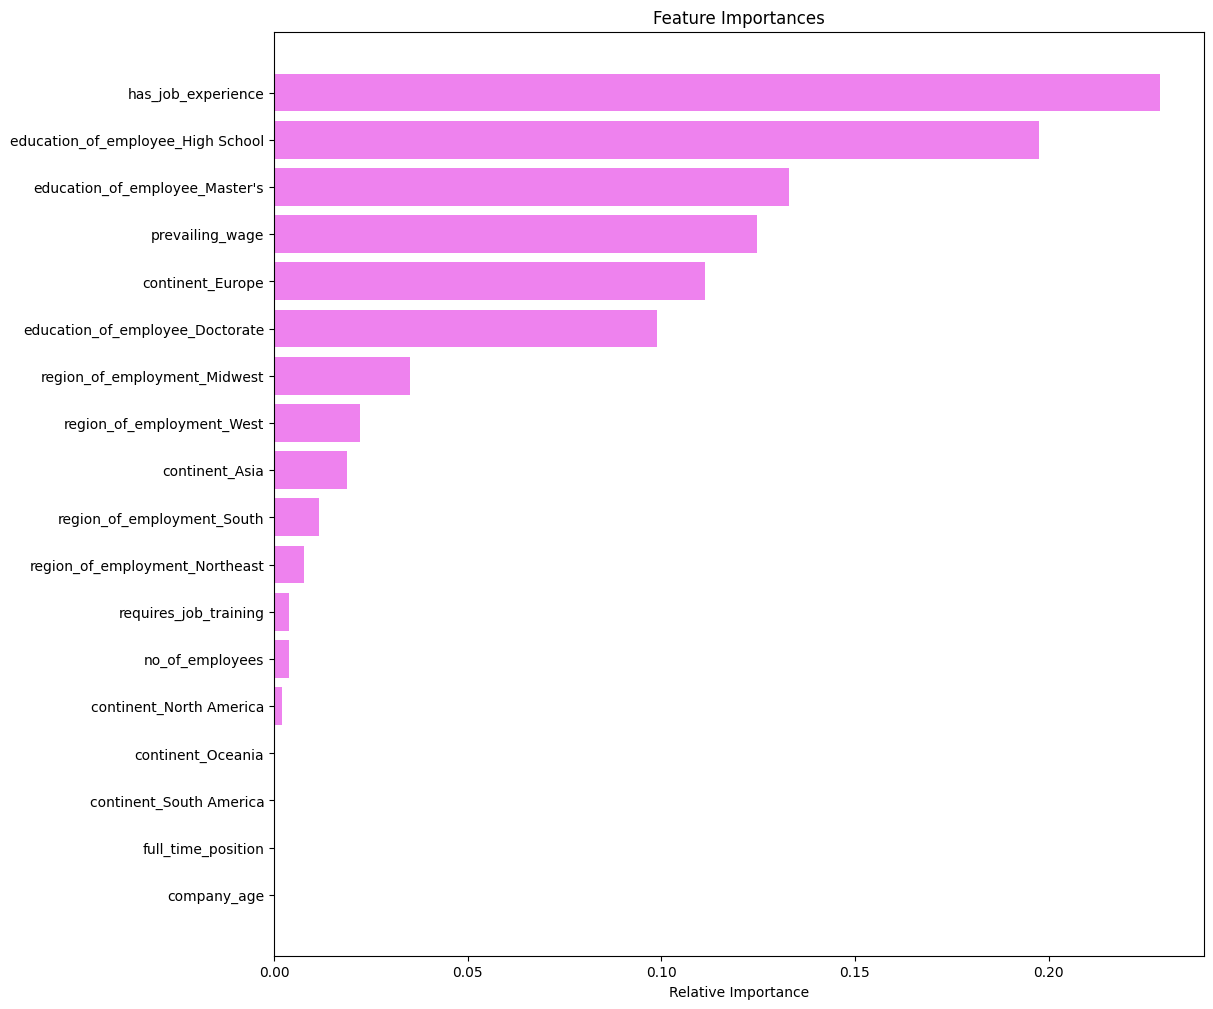

In [ ]:
feature_names = X_train.columns
importances = final_model.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(12, 12))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color="violet", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

**OBSERVATIONS**:
- **has_job_experience** is the most important feature
- **education_of_employee**, especially atleast High School, Master's or Doctoracte holds importance in approval.
- **prevailing_wage** is also an important factor. Since this is a treated column, so in the original dataset, prevailing_wage with unit_of_wage should both be considered.
- Certain other values like if the candidate is from the continent: Europe, region_of_employent as MidWest or West also hold a certain level of importance but not as much
- *full_time_postion* and ***yr_of_est/company_age*** hold **no importance** in determining the Visa application

## Actionable Insights and Recommendations

**OBSERVATIONS**:

---
**TECHNICAL INSIGHTS**:

---
***Overview***:
- We had been provided data of visa applicants regarding features pertaining to:
  - the applicant(like job experience),
  - the jobrole (like full_time_position) and
  - the company (like year of establishment) the candidate works for.
- We performed some data cleaning and optimization on the data for prevailing_wage etc and based on the univariant and bivariant analysis, most of the features had significant data which potentially contributed to the case_status being Certified or Rejected.
- We built a few models to predict the case_status and optimize the models based on the Hyperparameter tuning and comparing the evaluation criteria

***Conclusion***:
- 'has_job_experience', 'education_of_employee' are the top two features which are important in determining the visa status.
- Features like 'prevailing_wage', and certain values of some features like continent of Europe or region_of_employment as MidWest or West also hold importance in the descending order of importance.
- Based on the comparison of 6 models
  - GradientBoost Classifier,
  - AdaBoost Classifier,
  - DecisionTreeClassifier,
  - XGBoost Classifier,
  - Random Forest Classifier and
  - Bagging Classifier

  with:
  - original cleaned data ,
  - data with oversampling,
  - data with undersampling

  and comparison of
  - training data and
  - validation data

  for choosing the best model with hyperparameter tuning, we conclude that we have a model: AdaBoostClassifier which can be used to predict if the Visa application will be Certified or Denied for any unknown application (test set) 81% accuracy of f1_score.


***Final Model Selection***:
- AdaBoostClassifier on original training data



---

**BUSINESS INSIGHTS**:

---

- For the Visa approval process optimization
  - To speed up the process, we can use the Machine Learning Model we trained: AdaBoostClassifier to prescreen the candidates to predict if their visa should be approved or not.
  - By setting a threshold, the Visa applications which have a high probability of rejection can be routed to a different process for request for more information or valid rejections if the rules and criteria apply.
  - This can help funnelize the process and reduce the workload.
  - The rest of the applications can be sent for document verification and further screening and evaluation. By this time, the reviewer will already have more insight into the application, given the results of prescreening using the Model which can help further speed up the process.

- For candidates
  - The visa applicants should build a portfolio
    - with job experience present,
    - with atleast HighSchool's or Master's level of education,
    - with higher prevailing wage
  to have a greater chance of Visa Approvals.
  - Candidate's from Europe also have a higher change of visa approvals.
  - Other factors also play importance but if it is full_time_position or not and how old the company is has no importance to the Visa selection.


